In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit


In [2]:
data = sm.datasets.sunspots.load_pandas().data

X = np.arange(len(data)).reshape(-1, 1)
y = data['SUNACTIVITY'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)


In [3]:
# One hidden layer with 50 neurons
mlp_1 = MLPRegressor(hidden_layer_sizes=(50,), activation='relu', solver='adam',
max_iter=2500)
mlp_1.fit(X_train, y_train)

# 5 layers with 50 neurons
mlp_5 = MLPRegressor(hidden_layer_sizes=(50, 50, 50, 50, 50,), activation='relu', solver='adam',
max_iter=2500)
mlp_5.fit(X_train, y_train)

# Predict and evaluate MLPs
y_pred_mlp_1 = mlp_1.predict(X_test)
y_pred_mlp_5 = mlp_5.predict(X_test)

print("MLP (1 layer) MSE:", mean_squared_error(y_test, y_pred_mlp_1))
print("MLP (5 layer) MSE:", mean_squared_error(y_test, y_pred_mlp_5))

print("MLP (1 layer) RMSE;", root_mean_squared_error(y_test, y_pred_mlp_1))
print("MLP (5 layer) RMSE;", root_mean_squared_error(y_test, y_pred_mlp_5))

MLP (1 layer) MSE: 3323.1516050950586
MLP (5 layer) MSE: 2900.6225719844856
MLP (1 layer) RMSE; 57.64678312876668
MLP (5 layer) RMSE; 53.85742819690229


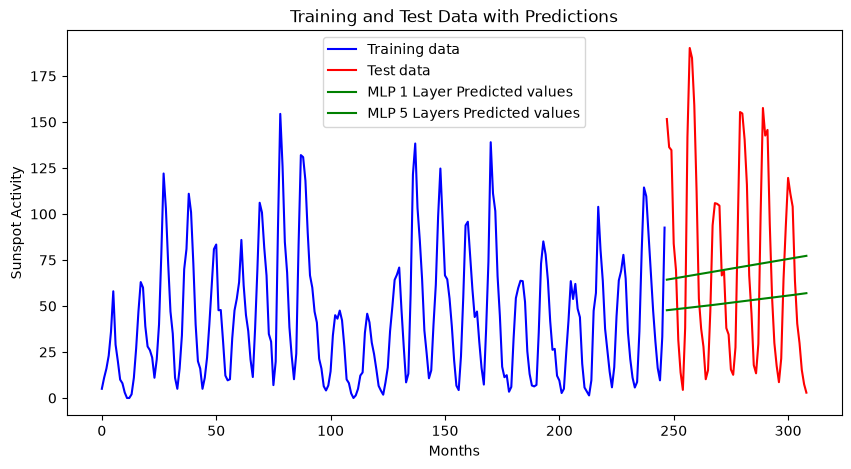

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(X_train[:, -1], y_train, 'b-', label='Training data')
plt.plot(X_test, y_test, 'r-', label='Test data')
plt.plot(X_test, y_pred_mlp_1, 'g-', label='MLP 1 Layer Predicted values')
plt.plot(X_test, y_pred_mlp_5, 'g-', label='MLP 5 Layers Predicted values')
plt.legend()
plt.title('Training and Test Data with Predictions')
plt.xlabel('Months')
plt.ylabel('Sunspot Activity')
plt.show()